<a href="https://colab.research.google.com/github/balajimohan573-collab/Machine_learning/blob/main/ml_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
     Sky Temperature Humidity    Wind Water Forecast EnjoySport
0  Sunny        Warm   Normal  Strong  Warm     Same        Yes
1  Sunny        Warm     High  Strong  Warm     Same        Yes
2  Rainy        Cold     High  Strong  Warm   Change         No
3  Sunny        Warm     High  Strong  Cool   Change        Yes

Final Most Specific Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']


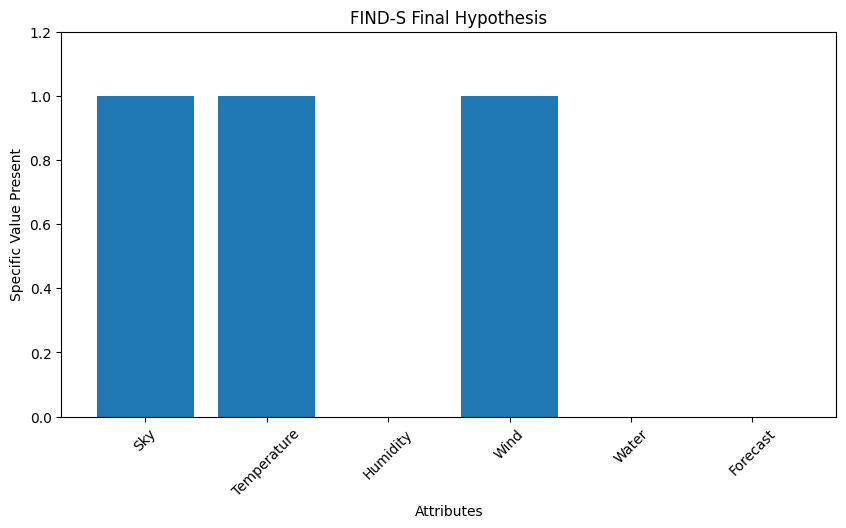

In [ ]:
#PROGRAM(1)
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High',   'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High',   'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High',   'Strong', 'Cool', 'Change', 'Yes']
]

columns = [
    'Sky', 'Temperature', 'Humidity',
    'Wind', 'Water', 'Forecast', 'EnjoySport'
]

df = pd.DataFrame(data, columns=columns)

print("Training Data:")
print(df)

# FIND-S Algorithm
hypothesis = ['0'] * 6

for i in range(len(df)):

    # Consider only positive examples
    if df.iloc[i, 6] == 'Yes':

        for j in range(6):

            if hypothesis[j] == '0':
                hypothesis[j] = df.iloc[i, j]

            elif hypothesis[j] != df.iloc[i, j]:
                hypothesis[j] = '?'

print("\nFinal Most Specific Hypothesis:")
print(hypothesis)

# -------------------------------
# MATPLOTLIB VISUALIZATION
# -------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    columns[:6],
    [1 if x != '?' else 0 for x in hypothesis]
)

plt.title("FIND-S Final Hypothesis")
plt.xlabel("Attributes")
plt.ylabel("Specific Value Present")

plt.xticks(rotation=45)
plt.ylim(0, 1.2)

plt.show()

Training Data:
     Sky Temperature Humidity    Wind Water Forecast EnjoySport
0  Sunny        Warm   Normal  Strong  Warm     Same        Yes
1  Sunny        Warm     High  Strong  Warm     Same        Yes
2  Rainy        Cold     High  Strong  Warm   Change         No
3  Sunny        Warm     High  Strong  Cool   Change        Yes

Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', '?', '?']

General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']


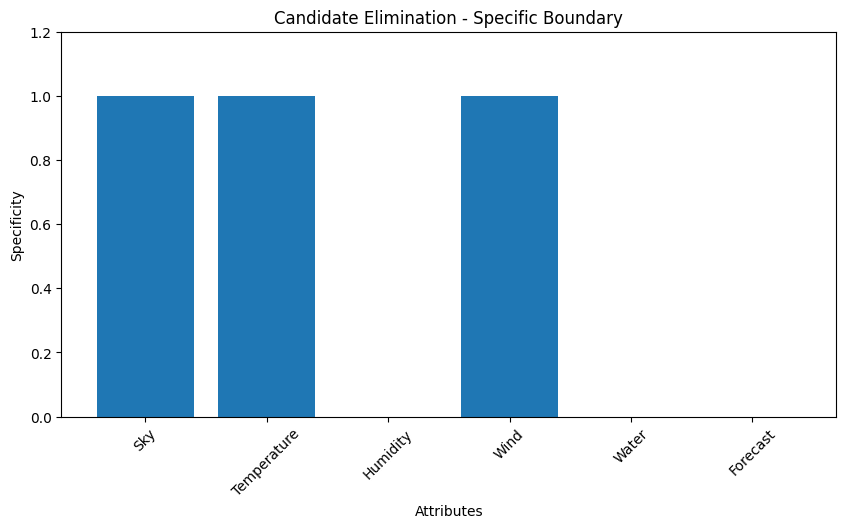

In [ ]:
#PROGRAM2

import pandas as pd
import matplotlib.pyplot as plt

# Create training dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'Temperature': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save as CSV
df.to_csv('training_data.csv', index=False)

# Read CSV
df = pd.read_csv('training_data.csv')

print("Training Data:")
print(df)

# Attributes
attributes = list(df.columns[:-1])

# Initialize Specific and General hypotheses
S = ['0'] * len(attributes)
G = [['?'] * len(attributes)]

# Candidate Elimination
for _, row in df.iterrows():

    example = row.iloc[:-1].tolist()
    label = row.iloc[-1]

    if label == 'Yes':

        # Remove inconsistent general hypotheses
        G = [
            g for g in G
            if all(g[i] == '?' or g[i] == example[i] for i in range(len(attributes)))
        ]

        # Generalize S
        for i in range(len(attributes)):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

    else:

        # Remove hypotheses from G that cover negative example
        new_G = []

        for g in G:
            if all(g[i] == '?' or g[i] == example[i]
                   for i in range(len(attributes))):

                for i in range(len(attributes)):
                    if g[i] == '?':
                        if S[i] != '?' and S[i] != example[i]:
                            new_g = g.copy()
                            new_g[i] = S[i]
                            new_G.append(new_g)
            else:
                new_G.append(g)

        G = new_G

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")
for g in G:
    print(g)

# -----------------------------
# MATPLOTLIB VISUALIZATION
# -----------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    attributes,
    [0 if value == '?' else 1 for value in S]
)

plt.title("Candidate Elimination - Specific Boundary")
plt.xlabel("Attributes")
plt.ylabel("Specificity")

plt.xticks(rotation=45)
plt.ylim(0, 1.2)

plt.show()

Training Data:
     Sky Temperature Humidity    Wind Play
0  Sunny         Hot     High    Weak   No
1  Sunny         Hot     High  Strong   No
2  Rainy        Cold     High    Weak  Yes
3  Sunny        Warm     High    Weak  Yes
4  Rainy        Cold   Normal    Weak  Yes
5  Rainy        Cold   Normal  Strong   No
6  Sunny        Warm   Normal  Strong  Yes
7  Sunny         Hot     High    Weak   No
8  Rainy        Cold   Normal    Weak  Yes
9  Sunny        Warm   Normal  Strong  Yes

New Sample:
   Sky_Rainy  Sky_Sunny  Temperature_Cold  Temperature_Hot  Temperature_Warm  \
0          0       True                 0                0              True   

   Humidity_High  Humidity_Normal  Wind_Strong  Wind_Weak  
0              0             True         True          0  

Prediction:
Yes


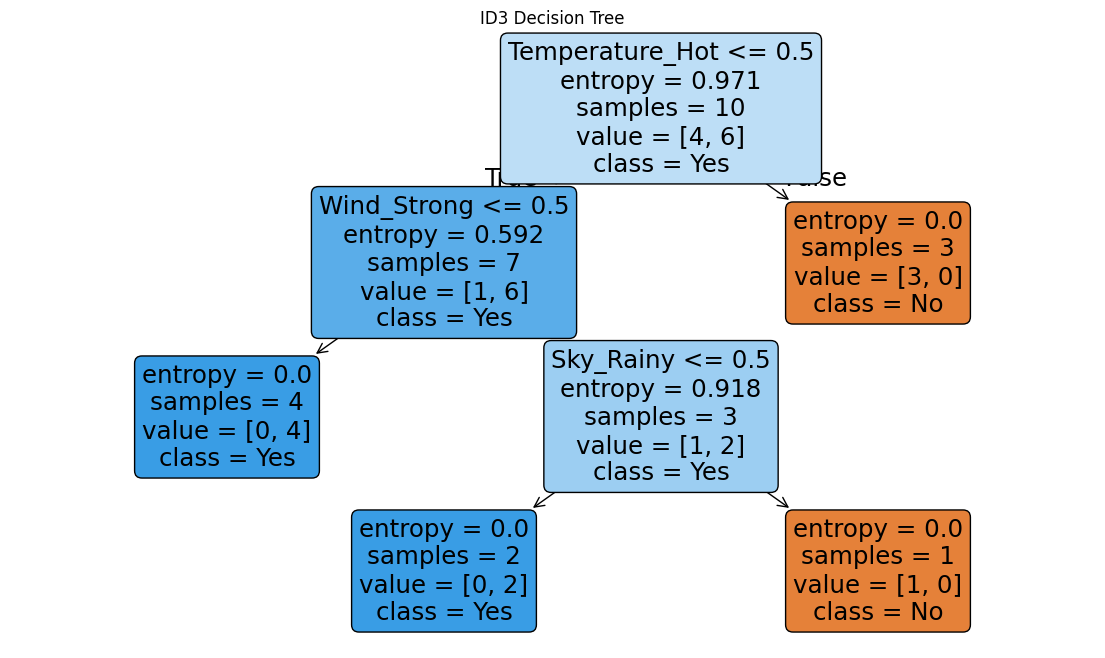

In [ ]:
PROGRAM(3)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny', 'Rainy', 'Rainy', 'Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'Temperature': ['Hot', 'Hot', 'Cold', 'Warm', 'Cold', 'Cold', 'Warm', 'Hot', 'Cold', 'Warm'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Strong'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# Convert categorical values to numbers
X = pd.get_dummies(df.iloc[:, :-1])
y = df['Play'].map({'No': 0, 'Yes': 1})

# ID3 Decision Tree
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)

# New sample
new_sample = pd.DataFrame([{
    'Sky': 'Sunny',
    'Temperature': 'Warm',
    'Humidity': 'Normal',
    'Wind': 'Strong'
}])

# Convert new sample using same columns
new_sample = pd.get_dummies(new_sample)
new_sample = new_sample.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_sample)

result = 'Yes' if prediction[0] == 1 else 'No'

print("\nNew Sample:")
print(new_sample)

print("\nPrediction:")
print(result)

# -----------------------------
# MATPLOTLIB VISUALIZATION
# -----------------------------

plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True
)

plt.title("ID3 Decision Tree")
plt.show()

Input Data:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

Target Output:
[0 1 1 0]

Actual Output:
[1 0]

Predicted Output:
[0 1]

Accuracy: 0.0 %

New Data Prediction:
[0 0] -> 0
[0 1] -> 0
[1 0] -> 1
[1 1] -> 1


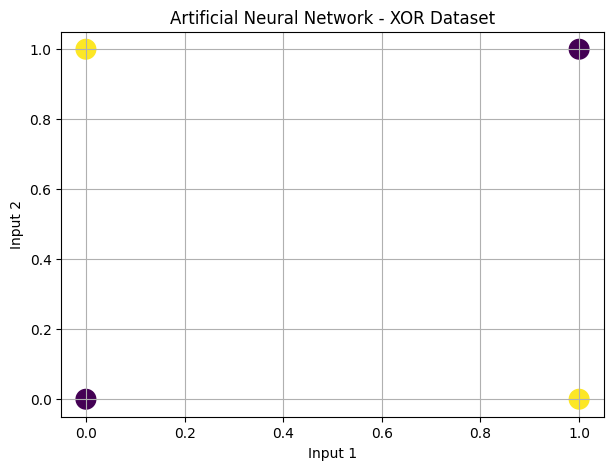

In [ ]:
#PROGRAM(4)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# -----------------------------
# 1. DATASET
# -----------------------------

# Simple XOR dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 0])

print("Input Data:")
print(X)

print("\nTarget Output:")
print(y)


# -----------------------------
# 2. SPLIT DATA
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=42
)


# -----------------------------
# 3. ARTIFICIAL NEURAL NETWORK
# -----------------------------

model = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation='relu',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

# Train the ANN
model.fit(X_train, y_train)


# -----------------------------
# 4. PREDICTION
# -----------------------------

y_pred = model.predict(X_test)

print("\nActual Output:")
print(y_test)

print("\nPredicted Output:")
print(y_pred)


# -----------------------------
# 5. ACCURACY
# -----------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy * 100, "%")


# -----------------------------
# 6. TEST NEW DATA
# -----------------------------

new_data = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

prediction = model.predict(new_data)

print("\nNew Data Prediction:")
for i in range(len(new_data)):
    print(new_data[i], "->", prediction[i])


# -----------------------------
# 7. MATPLOTLIB VISUALIZATION
# -----------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    s=200
)

plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("Artificial Neural Network - XOR Dataset")

plt.grid()
plt.show()